In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [2]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
data_dir = Path("data")

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding = 4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dataset = datasets.CIFAR10(root = data_dir, train = True, download = True, transform = train_transform)
test_dataset = datasets.CIFAR10(root = data_dir, train = False, download = True, transform = test_transform)

In [4]:
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True, num_workers = 2)
test_loader = DataLoader(test_dataset, batch_size = batch_size, shuffle = False, num_workers = 2)

image, label = train_dataset[0]
images_batch, labels_batch = next(iter(train_loader))
print(f"Количество изображений в выборке train: {len(train_dataset)}")
print(f"Количество изображений в выборке test: {len(test_dataset)}")
print(f"Первое изображение в train: метка = {label}, класс = {train_dataset.classes[label]}")
print(f"Форма одного изображения: {image.shape}")
print(f"Форма одной метки: {torch.tensor(label).shape}")

Количество изображений в выборке train: 50000
Количество изображений в выборке test: 10000
Первое изображение в train: метка = 6, класс = frog
Форма одного изображения: torch.Size([3, 32, 32])
Форма одной метки: torch.Size([])


In [5]:
class_names = train_dataset.classes
print(f"Классы: {class_names}")

Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Изображения из выборки train:


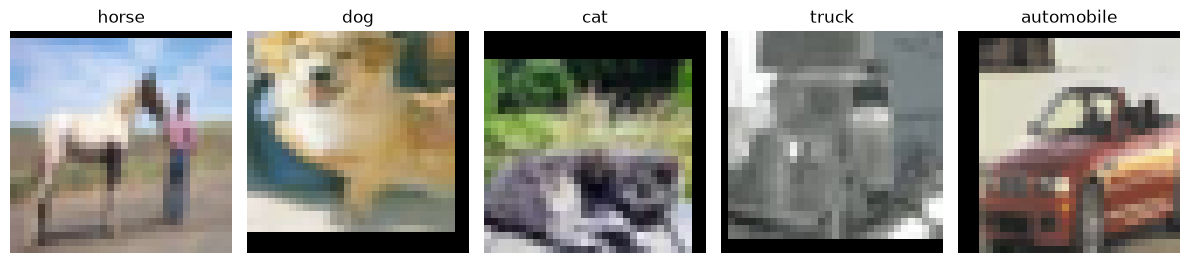

Изображения из выборки test:


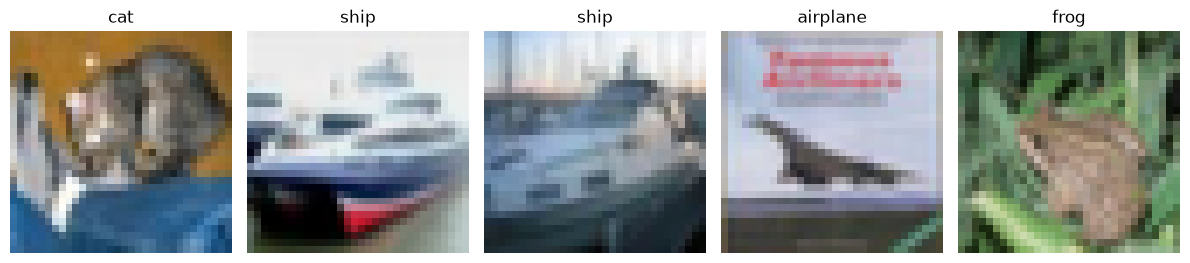

In [6]:
mean_tensor = torch.tensor(mean).view(3, 1, 1)
std_tensor = torch.tensor(std).view(3, 1, 1)

def show_image(image_tensor):
    image_tensor = image_tensor.cpu() * std_tensor + mean_tensor
    image_tensor = image_tensor.clamp(0, 1)
    return image_tensor.permute(1, 2, 0).numpy()

print("Изображения из выборки train:")
images, labels = next(iter(train_loader))
plt.figure(figsize = (12, 6))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(show_image(images[i]))
    plt.title(class_names[labels[i].item()])
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Изображения из выборки test:")
images_t, labels_t = next(iter(test_loader))
plt.figure(figsize = (12, 6))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(show_image(images_t[i]))
    plt.title(class_names[labels_t[i].item()])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [7]:
class SimpleVGG(nn.Module):
    def __init__(self, number_of_classes = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, number_of_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [8]:
model = SimpleVGG().to(device)
print(model)

number_of_parameters = sum(p.numel() for p in model.parameters())
print(f"\nКоличество параметров: {number_of_parameters}")

SimpleVGG(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, ke

In [9]:
learning_rate = 0.001
epochs = 40

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate)

In [10]:
def train_one_epoch(model, data_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct_predictions = 0
    total_examples = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim = 1)
        correct_predictions += (predictions == labels).sum().item()
        total_examples += labels.size(0)

    average_loss = total_loss / total_examples
    accuracy = correct_predictions / total_examples
    return average_loss, accuracy

train_errors = []
for epoch in range(1, epochs + 1):
    train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, device)
    classification_error = 1 - train_accuracy
    train_errors.append(classification_error)
    print(f"{epoch} эпоха: ошибка классификации = {classification_error:.2%}, точность = {train_accuracy:.2%}")

1 эпоха: ошибка классификации = 59.35%, точность = 40.65%
2 эпоха: ошибка классификации = 42.07%, точность = 57.93%
3 эпоха: ошибка классификации = 34.92%, точность = 65.08%
4 эпоха: ошибка классификации = 30.75%, точность = 69.25%
5 эпоха: ошибка классификации = 27.62%, точность = 72.38%
6 эпоха: ошибка классификации = 25.11%, точность = 74.89%
7 эпоха: ошибка классификации = 23.26%, точность = 76.74%
8 эпоха: ошибка классификации = 21.82%, точность = 78.18%
9 эпоха: ошибка классификации = 20.47%, точность = 79.53%
10 эпоха: ошибка классификации = 19.60%, точность = 80.40%
11 эпоха: ошибка классификации = 18.46%, точность = 81.54%
12 эпоха: ошибка классификации = 17.46%, точность = 82.54%
13 эпоха: ошибка классификации = 16.78%, точность = 83.22%
14 эпоха: ошибка классификации = 16.11%, точность = 83.89%
15 эпоха: ошибка классификации = 15.79%, точность = 84.21%
16 эпоха: ошибка классификации = 14.98%, точность = 85.02%
17 эпоха: ошибка классификации = 14.36%, точность = 85.64%
18 эпо

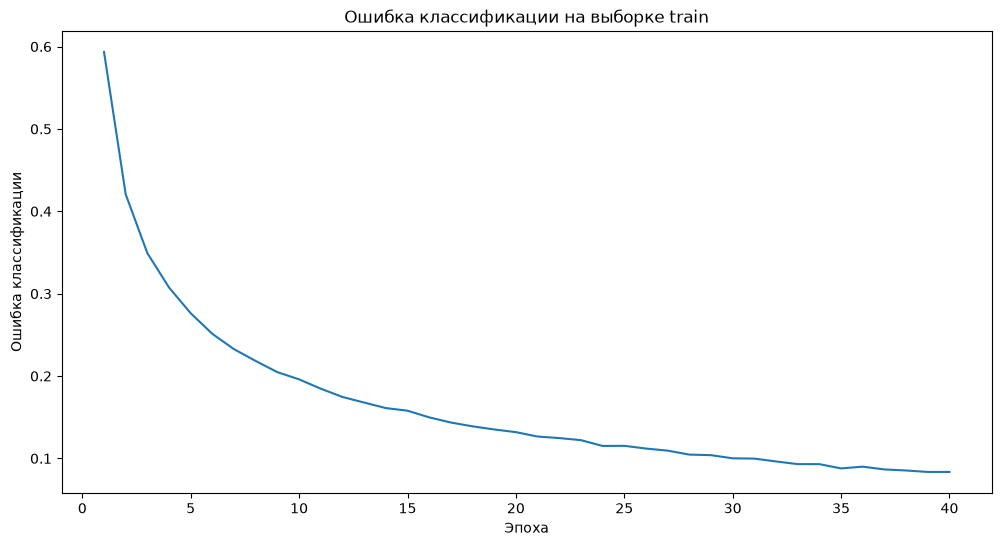

In [11]:
plt.figure(figsize = (12, 6))
plt.plot(range(1, epochs + 1), train_errors)
plt.title("Ошибка классификации на выборке train")
plt.xlabel("Эпоха")
plt.ylabel("Ошибка классификации")
plt.show()

In [12]:
model.eval()
correct_predictions = 0
total_examples = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim = 1)

        correct_predictions += (predictions == labels).sum().item()
        total_examples += labels.size(0)

test_accuracy = correct_predictions / total_examples
test_error = 1 - test_accuracy
print(f"Точность на выборке test: {test_accuracy:.2%}")
print(f"Ошибка классификации на выборке test: {test_error:.2%}")

Точность на выборке test: 87.91%
Ошибка классификации на выборке test: 12.09%


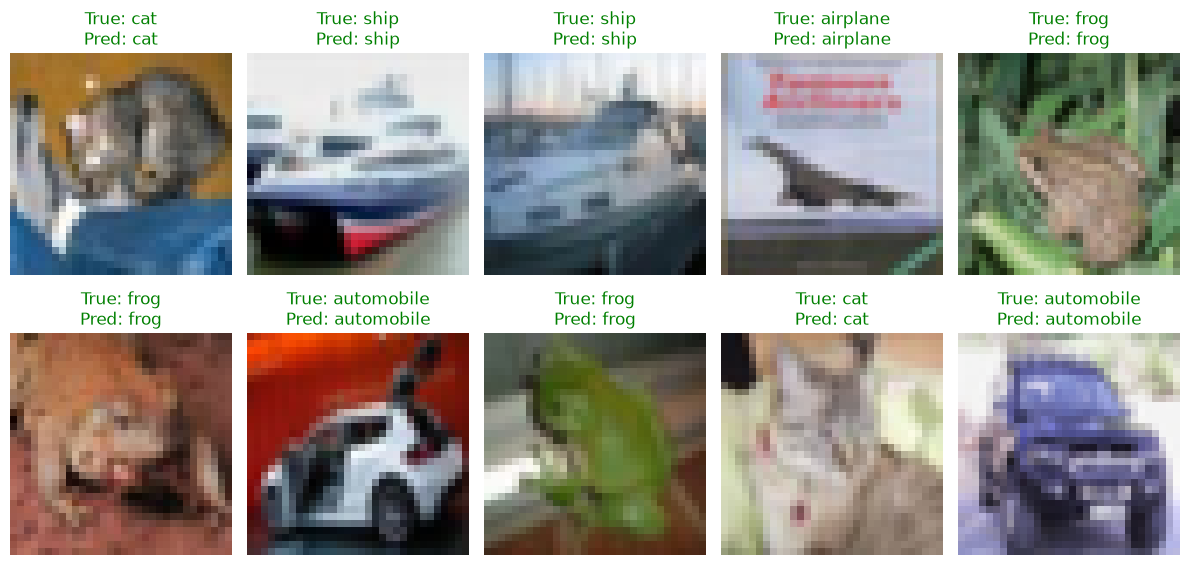

In [13]:
images, labels = next(iter(test_loader))
with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim = 1).cpu()

plt.figure(figsize = (12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(show_image(images[i]))
    if predictions[i] == labels[i]:
        color = "green"
    else: 
        color ="red"
    plt.title(f"True: {class_names[labels[i].item()]}\nPred: {class_names[predictions[i].item()]}", color = color)
    plt.axis("off")
plt.tight_layout()
plt.show()